# Phase 3 — Evaluation Protocol & Baselines

> **Protocol locked before model comparison**
>
> - **Forecast origin:** end of July. July's value is assumed known at July month-end (the Census publishes with a lag; if operational forecasts are issued earlier, move the origin back).
> - **Horizon:** the next 12 calendar months, **August through July**.
> - **Validation folds** (model selection): Jul 2016, 2017, 2018, 2019, 2022, 2023.
> - **Stress folds** (COVID, reported separately and unmasked, never used to select): Jul 2020, 2021.
> - **Test folds** (the most recent 24 months, Aug 2024 – Jul 2026): Jul 2024, 2025. **Locked in code:** only `evaluate(..., final=True)` can score them, once, at the very end.
> - **Training boundary:** every forecast function receives only the series through that fold's `train_end`.
> - **Scoring mask:** exclude target months **Mar 2020 – Jun 2021** from primary scoring.
> - **Success bar for models:** pooled RelMAE ≤ **0.90** versus seasonal naive **and** beat it in at least **4 of 6** validation folds.
> - **Drift estimators:** growth is computed only from YoY rows whose current and comparison months are unmasked. The trailing-12 estimator falls back to zero drift when fewer than 6 clean observations exist.
> - **December:** absolute percentage error; one December per fold is not enough to infer a calendar-placement effect.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis.eda_helper import load_apparel_data
from src.evaluation import (
    VALIDATION_ORIGINS, STRESS_ORIGINS, TEST_ORIGINS, MASK_START, MASK_END, MIN_TRAILING_OBS,
    get_forecast_folds, seasonal_naive_forecast, make_drift_forecaster,
    trailing_growth, eligible_yoy_growth, evaluate,
)

y = load_apparel_data()["apparel_sales_nsa"].dropna().astype(float)
print(f"Dataset: {len(y):,} monthly observations, {y.index.min():%Y-%m} to {y.index.max():%Y-%m}\n")
for label, origins in [("VALIDATION", VALIDATION_ORIGINS), ("STRESS", STRESS_ORIGINS), ("TEST (locked)", TEST_ORIGINS)]:
    for fold in get_forecast_folds(origins, data_end=y.index.max()):
        m = fold["forecast_months"]
        print(f"{label:14s} origin {fold['origin']:%Y-%m} | train through {fold['train_end']:%Y-%m} | forecast {m[0]:%Y-%m} to {m[-1]:%Y-%m}")

Dataset: 415 monthly observations, 1992-01 to 2026-07

VALIDATION     origin 2016-07 | train through 2016-07 | forecast 2016-08 to 2017-07
VALIDATION     origin 2017-07 | train through 2017-07 | forecast 2017-08 to 2018-07
VALIDATION     origin 2018-07 | train through 2018-07 | forecast 2018-08 to 2019-07
VALIDATION     origin 2019-07 | train through 2019-07 | forecast 2019-08 to 2020-07
VALIDATION     origin 2022-07 | train through 2022-07 | forecast 2022-08 to 2023-07
VALIDATION     origin 2023-07 | train through 2023-07 | forecast 2023-08 to 2024-07
STRESS         origin 2020-07 | train through 2020-07 | forecast 2020-08 to 2021-07
STRESS         origin 2021-07 | train through 2021-07 | forecast 2021-08 to 2022-07
TEST (locked)  origin 2024-07 | train through 2024-07 | forecast 2024-08 to 2025-07
TEST (locked)  origin 2025-07 | train through 2025-07 | forecast 2025-08 to 2026-07


### Split diagram

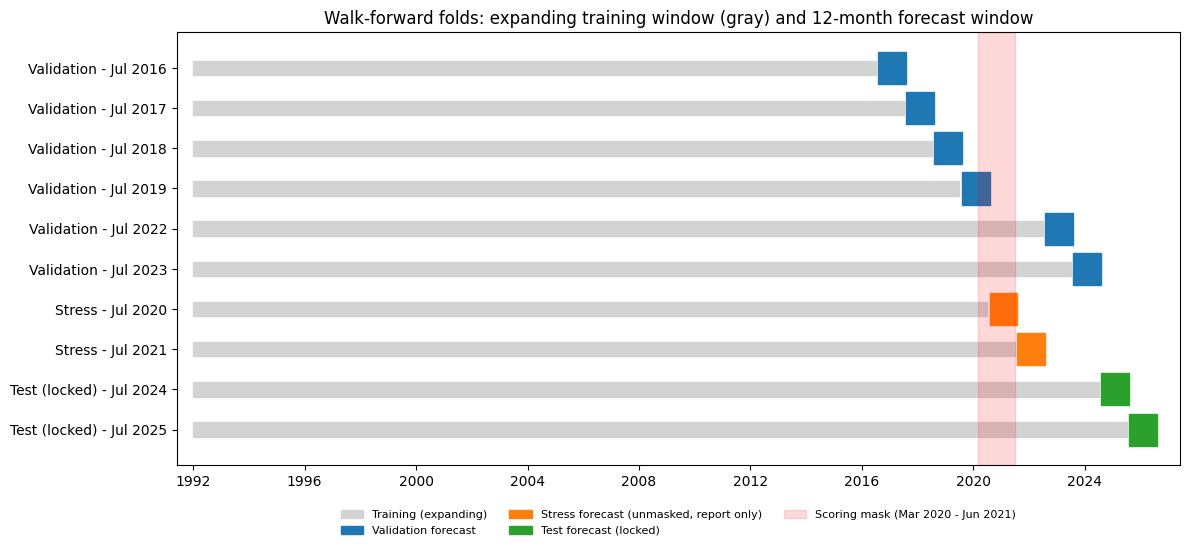

In [2]:
rows = ([("Validation", o, "tab:blue") for o in VALIDATION_ORIGINS]
        + [("Stress", o, "tab:orange") for o in STRESS_ORIGINS]
        + [("Test (locked)", o, "tab:green") for o in TEST_ORIGINS])

fig, ax = plt.subplots(figsize=(12, 5.6))
start_num = mdates.date2num(y.index.min())
for i, (group, origin, color) in enumerate(rows):
    fold = get_forecast_folds([origin], data_end=y.index.max())[0]
    train_end = mdates.date2num(fold["train_end"])
    f0 = mdates.date2num(fold["forecast_months"][0])
    f1 = mdates.date2num(fold["forecast_months"][-1] + pd.offsets.MonthEnd(0))
    ax.broken_barh([(start_num, train_end - start_num)], (i - 0.18, 0.36), color="lightgray")
    ax.broken_barh([(f0, f1 - f0)], (i - 0.4, 0.8), color=color)
ax.axvspan(mdates.date2num(MASK_START), mdates.date2num(MASK_END), color="red", alpha=0.15)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{g} - Jul {pd.Timestamp(o).year}" for g, o, _ in rows])
ax.invert_yaxis()
ax.xaxis_date()
ax.set_title("Walk-forward folds: expanding training window (gray) and 12-month forecast window")
ax.legend(handles=[Patch(color="lightgray", label="Training (expanding)"),
                   Patch(color="tab:blue", label="Validation forecast"),
                   Patch(color="tab:orange", label="Stress forecast (unmasked, report only)"),
                   Patch(color="tab:green", label="Test forecast (locked)"),
                   Patch(color="red", alpha=0.15, label="Scoring mask (Mar 2020 - Jun 2021)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, frameon=False)
ax.set_xlim(mdates.date2num(pd.Timestamp("1991-06-01")), mdates.date2num(pd.Timestamp("2027-06-01")))
fig.tight_layout()
(project_root / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(project_root / "reports" / "figures" / "split_diagram.png", dpi=150)
plt.show()

### Drift selection on the six validation folds

In [3]:
candidate_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    "Drift: masked mean YoY": make_drift_forecaster("mean_all"),
    "Drift: masked median YoY": make_drift_forecaster("median_all"),
    "Drift: trailing-12-month mean YoY": make_drift_forecaster("mean_trailing12"),
}
# evaluate() defaults to VALIDATION_ORIGINS and refuses the locked test origins.
validation_tables = {name: evaluate(fn, y) for name, fn in candidate_forecasters.items()}

drift_names = [n for n in candidate_forecasters if n != "Seasonal Naive"]
pooled_scores = {n: validation_tables[n]["MAE"].sum() / validation_tables[n]["Benchmark_SN_MAE"].sum() for n in drift_names}
best_drift_name = min(pooled_scores, key=pooled_scores.get)
print("Pooled RelMAE vs seasonal naive (six validation folds):")
print(pd.Series(pooled_scores, name="Pooled RelMAE").sort_values().round(3))
print(f"\nSelected drift baseline: {best_drift_name}")

# How many clean YoY observations feed each drift estimate, per fold?
rate_rows = []
for fold in get_forecast_folds(VALIDATION_ORIGINS, data_end=y.index.max()):
    train = y.loc[:fold["train_end"]]
    growth = eligible_yoy_growth(train)
    t_rate, t_n = trailing_growth(train)
    rate_rows.append({"Origin": f"{fold['origin']:%Y-%m}", "All_history_mean_%": growth.mean() * 100,
                      "All_history_median_%": growth.median() * 100, "Trailing12_%": t_rate * 100,
                      "Trailing12_n_obs": t_n, "Zero_drift_fallback": t_n < MIN_TRAILING_OBS})
rate_df = pd.DataFrame(rate_rows)
display(rate_df.round(2))
print(f"Folds using the zero-drift fallback: {int(rate_df['Zero_drift_fallback'].sum())}")

Pooled RelMAE vs seasonal naive (six validation folds):
Drift: trailing-12-month mean YoY    0.930
Drift: masked mean YoY               1.060
Drift: masked median YoY             1.132
Name: Pooled RelMAE, dtype: float64

Selected drift baseline: Drift: trailing-12-month mean YoY


,Origin,All_history_mean_%,All_history_median_%,Trailing12_%,Trailing12_n_obs,Zero_drift_fallback
0,2016-07,3.47,3.86,1.33,12,False
1,2017-07,3.37,3.72,0.87,12,False
2,2018-07,3.29,3.61,1.35,12,False
3,2019-07,3.19,3.40,0.77,12,False
4,2022-07,3.16,3.38,-2.39,1,True
5,2023-07,3.07,3.31,0.82,12,False


Folds using the zero-drift fallback: 1


In [4]:
sn_results = validation_tables["Seasonal Naive"]
drift_results = validation_tables[best_drift_name]

results_df = sn_results[["Origin", "Train_End", "Scored_Months", "MAE", "RMSE", "Bias", "December_Abs_Pct_Error"]].rename(columns={
    "MAE": "SN_MAE", "RMSE": "SN_RMSE", "Bias": "SN_Bias", "December_Abs_Pct_Error": "SN_Dec_Abs_Pct_Error"})
results_df["Drift_MAE"] = drift_results["MAE"].to_numpy()
results_df["Drift_RelMAE"] = drift_results["RelMAE_vs_SN"].to_numpy()
results_df["Drift_Dec_Abs_Pct_Error"] = drift_results["December_Abs_Pct_Error"].to_numpy()
display(results_df.round(3))

pooled_relmae = drift_results["MAE"].sum() / sn_results["MAE"].sum()
fold_wins = int((drift_results["RelMAE_vs_SN"] < 0.9999).sum())
fold_ties = int(np.isclose(drift_results["RelMAE_vs_SN"], 1.0).sum())
print(f"Pooled RelMAE for selected drift: {pooled_relmae:.3f}")
print(f"Folds beating seasonal naive: {fold_wins}/6 (ties: {fold_ties})")
print("Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds):", pooled_relmae <= 0.90 and fold_wins >= 4)

,Origin,Train_End,Scored_Months,SN_MAE,SN_RMSE,SN_Bias,SN_Dec_Abs_Pct_Error,Drift_MAE,Drift_RelMAE,Drift_Dec_Abs_Pct_Error
0,2016-07,2016-07,12,434.667,564.338,-217.500,3.557,387.981,0.893,2.279
1,2017-07,2017-07,12,590.667,718.648,-261.167,2.606,564.731,0.956,3.499
2,2018-07,2018-07,12,385.167,480.673,-157.833,0.351,425.031,1.103,0.995
3,2019-07,2019-07,7,601.571,709.364,-483.571,3.188,529.464,0.880,2.441
4,2022-07,2022-07,12,526.083,635.634,-142.250,1.165,526.083,1.000,1.165
5,2023-07,2023-07,12,668.000,807.580,-578.333,3.525,549.075,0.822,2.734


Pooled RelMAE for selected drift: 0.930
Folds beating seasonal naive: 4/6 (ties: 1)
Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds): False


### COVID stress folds (unmasked, report only)

In [5]:
for name in ["Seasonal Naive", best_drift_name]:
    print(name)
    display(evaluate(candidate_forecasters[name], y, STRESS_ORIGINS, mask=False).round(2))

Seasonal Naive


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7039.75,7039.75,9157.31,-3594.58,1.0,12.29
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.0,18.85


Drift: trailing-12-month mean YoY


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7235.86,7039.75,9151.65,-3189.28,1.03,14.87
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.00,18.85


## Findings & Interpretation

**Seasonal naive (the benchmark).** Bias is negative in all six validation folds (-578 to -142 $M per month), so it under-forecasts every time. MAE ranges 385–668 $M and RMSE 481–808 $M. The 2019 fold scores only 7 of 12 months because the mask removes March–July 2020.

**December.** Seasonal-naive December error is 0.35%–3.56% of December sales, the same order as a typical month. One December per fold is too little data to explain it, so no calendar or weekend explanation is claimed.

**Drift selection (six validation folds, fixed rule: lowest pooled RelMAE).** Pooled RelMAE vs. seasonal naive: masked mean YoY **1.060**, masked median YoY **1.132**, trailing-12-month mean YoY **0.930**. Only the trailing-12 estimator beats seasonal naive pooled, so it is the selected drift baseline.

**Why long-run drift fails.** Seasonal naive under-forecasts, but adding the average growth of the whole history over-corrects. The all-history estimators imply about 3.1%–3.9% a year, while the trailing-12 estimate at the five clean origins was only 0.8%–1.4%. Recent growth was slower than the historical average, so the estimate has to be recent.

**The selected drift, fold by fold.** RelMAE [0.89, 0.96, 1.1, 0.88, 1.0, 0.82]. It beats seasonal naive in 4 folds, ties in 1 (2022-07: only 1 clean YoY observation survived the mask, so the rule falls back to zero drift) and loses in 1 (2018-07). Pooled RelMAE is **0.930**, so it **does not pass** the pre-declared bar (pooled ≤ 0.90 and at least 4 of 6 folds). Seasonal naive stays the benchmark that Phase 4 models must beat; this drift (0.93) is the stronger reference to report against.

**COVID stress folds (unmasked, report only, never used for selection).** Seasonal naive MAE is 7,040 $M (Jul 2020 origin) and 3,269 $M (Jul 2021 origin), with December errors of 12.3% and 18.8%. Drift does not help (RelMAE 1.03 and 1.00). When the base year is COVID-distorted, repeating last year fails; Phase 4 models need the training-time COVID treatment.

**Limits.** Six folds are a small, noisy sample. The protocol assumes July sales are known at the end of July.


## Tests

The fold contract, the scoring mask, the training-data boundary, the test-set lock and the drift fallback are covered by `pytest` (tests live in `src/tests/`, run from the repository root with `pytest`).

# Phase 4 Modeling Protocol

This section outlines the model selection framework, structural break handling (COVID-19 and the 2008 Great Recession), and scaling treatments used during Phase 4 modeling.

## 📅 Validation & Test Splits
The primary data used for model selection consists of six pre-declared validation folds. 
* **Validation Folds:** July 2016, 2017, 2018, 2019, 2022, and 2023.
* **Forecast Horizon:** Each forecast window spans a 12-month period from **August through July**.
* **Test Folds:** The July 2024 and July 2025 folds **remain locked** and are strictly excluded from Phase 4 evaluation.

## 😷 COVID-19 & Historical Shock Treatments
To isolate historical anomalies, training and scoring metrics handle data masks differently:

| Phase | Window | Treatment |
| :--- | :--- | :--- |
| **Training Mask** | March–June 2020 | Observations are removed from model fitting; **ETS** imputes these 4 missing values. |
| **Scoring Mask** | March 2020–June 2021 | Target values within this window are excluded from all primary error metrics. |

> 💡 **Note on Financial Crisis:** The 2008–2009 financial crisis remains completely intact within the training data without masking or imputation.

## 📈 Model Comparison & Scaling
* **Scale Evaluation:** Raw-scale and log-scale SARIMA candidates are directly compared using their **original-dollar forecasts**.
* **Log-Scale Bias:** For log-transformed models, exponentiation yields the *median* forecast rather than the conditional mean. The **dollar-scale bias metric** will be closely monitored to adjust for this transformation bias.


## Model Families and Candidate Specifications

The purpose of Phase 4 is to determine whether statistical forecasting models can improve on the seasonal-naive baseline for a 12-month inventory and staffing plan.

Three model families are evaluated:

### 1. Exponential Smoothing (ETS / Holt-Winters)

ETS captures the underlying sales trend and the recurring annual seasonal pattern. The implementation compares additive and multiplicative seasonality, each with an ordinary or damped trend.

The specification with the lowest corrected Akaike Information Criterion (AICc) is selected using the training data within each fold. The four COVID shock observations are imputed for ETS because the model cannot fit missing target values.

### 2. Seasonal ARIMA (SARIMA)

Two seasonal ARIMA candidates are investigated:

- SARIMA(0,1,1) × (0,1,1)₁₂
- SARIMA(0,1,2) × (0,1,1)₁₂

Both candidates are evaluated on raw sales and log-transformed sales. The model orders are compared using training-only AICc within each fold.

A separate D=0 alternative uses calendar-month dummy regressors with ARIMA errors. This candidate is motivated by the EDA finding that month dummies explained approximately 86.2% of the variation in log first differences.

### 3. Prophet

Prophet is evaluated with yearly seasonality enabled and daily and weekly seasonality disabled, since the target is monthly.

Both additive and multiplicative seasonality are considered, together with changepoint prior scales of 0.01, 0.05, and 0.2. These settings are compared using the six validation folds rather than in-sample fit.

Uncertainty sampling is disabled during point-forecast evaluation to reduce runtime. Forecast intervals are outside the scope of this phase.

### Fair Comparison

Every model receives only the training observations available at its forecast origin. Learned parameters and model specifications are estimated without using future validation or test observations.

All model predictions are returned on the original dollar scale and compared against the same actual observations and the same seasonal-naive benchmark.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.diagnostic import acorr_ljungbox

from src.analysis.eda_helper import load_apparel_data

from src.evaluation import (
    VALIDATION_ORIGINS,
    STRESS_ORIGINS,
    seasonal_naive_forecast,
    make_drift_forecaster,
    evaluate,
)

from src.models import (
    ets_forecast,
    sarima_raw_forecast,
    sarima_log_forecast,
    sarima_month_dummy_log_forecast,
    make_prophet_forecaster,
    fit_sarima_for_diagnostics,
    COVID_MONTHS
)


# Same sales target as Phase 3: NSA sales, in millions of dollars.
y = (
    load_apparel_data()["apparel_sales_nsa"]
    .dropna()
    .astype(float)
    .sort_index()
)

# ETS selects its smoothing specification inside each training fold.
# SARIMA selects its order inside each training fold.
# Prophet's seasonality mode and changepoint scale are compared
# using the six outer validation folds.

candidate_forecasters = {
    "ETS (AICc-selected)": ets_forecast,

    "SARIMA seasonal (raw)": sarima_raw_forecast,
    "SARIMA seasonal (log)": sarima_log_forecast,

    "SARIMAX log levels + month dummies (d=1, D=0)": (
        sarima_month_dummy_log_forecast
    ),
}

for mode in ("additive", "multiplicative"):
    for cps in (0.01, 0.05, 0.2):
        name = f"Prophet {mode}, cps={cps:g}"

        candidate_forecasters[name] = (
            make_prophet_forecaster(mode, cps)
        )


# Baselines from Phase 3.
baseline_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    "Drift: trailing-12-month mean YoY": (
        make_drift_forecaster("mean_trailing12")
    ),
}

all_forecasters = {
    **baseline_forecasters,
    **candidate_forecasters,
}

print("Target period:", y.index.min(), "to", y.index.max())
print("Number of monthly observations:", len(y))
print("Number of validation folds:", len(VALIDATION_ORIGINS))
print("Number of candidate models:", len(candidate_forecasters))

Target period: 1992-01-01 00:00:00 to 2026-07-01 00:00:00
Number of monthly observations: 415
Number of validation folds: 6
Number of candidate models: 10


In [7]:
validation_results = {}
prediction_records = []

for model_name, forecast_fn in all_forecasters.items():
    records = []

    result = evaluate(
        forecast_fn,
        y,
        origins=VALIDATION_ORIGINS,
        predictions_out=records,
    )

    result["Model"] = model_name
    validation_results[model_name] = result

    for record in records:
        record["Model"] = model_name
        prediction_records.append(record)


fold_metrics = pd.concat(
    validation_results.values(),
    ignore_index=True,
)

predictions = pd.DataFrame(prediction_records)
predictions["Date"] = pd.to_datetime(predictions["Date"])

scored = predictions.loc[
    predictions["Scored"]
].copy()

assert len(scored) > 0
assert scored["Error"].notna().all()
assert scored["AbsError"].notna().all()

print("Fold-metric rows:", len(fold_metrics))
print("Scored forecast observations:", len(scored))
print("Masked forecast observations:",
      int(predictions["Mask_Excluded"].sum()))

Importing plotly failed. Interactive plots will not work.
d:\GRIND\Data Analyst\Hiring-Projects\apparel-sales-forecasting\py_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fold-metric rows: 72
Scored forecast observations: 804
Masked forecast observations: 60


In [8]:
drift_name = "Drift: trailing-12-month mean YoY"

# Preserve the pooled RelMAE definition declared in Phase 3:
# sum of fold MAEs / sum of fold seasonal-naive MAEs.
sn_fold_mae_sum = validation_results["Seasonal Naive"]["MAE"].sum()

drift_fold_mae_sum = validation_results[drift_name]["MAE"].sum()

# Set the tie-break priority before ranking the candidates.
complexity_rank = {
    "ETS (AICc-selected)": 1,
    "SARIMA seasonal (raw)": 2,
    "SARIMA seasonal (log)": 3,
    "SARIMAX log levels + month dummies (d=1, D=0)": 4,
}

for i, cps in enumerate((0.01, 0.05, 0.2)):
    complexity_rank[f"Prophet additive, cps={cps:g}"] = 5 + i
    complexity_rank[f"Prophet multiplicative, cps={cps:g}"] = 8 + i


summary_rows = []

for model_name, model_folds in validation_results.items():
    model_fold_mae_sum = model_folds["MAE"].sum()

    model_predictions = scored.loc[
        scored["Model"] == model_name
    ]

    summary_rows.append({
        "Model": model_name,

        "Pooled_RelMAE_vs_SN": (
            model_fold_mae_sum / sn_fold_mae_sum
        ),

        "Pooled_RelMAE_vs_Drift": (
            model_fold_mae_sum / drift_fold_mae_sum
        ),

        "Folds_Beating_SN": int(
            (model_folds["RelMAE_vs_SN"] < 1.0).sum()
        ),

        "Mean_Bias": model_predictions["Error"].mean(),

        "Mean_December_Abs_Pct_Error": (
            model_folds["December_Abs_Pct_Error"].mean()
        ),

        "Complexity_Rank": complexity_rank.get(
            model_name, 99
        ),
    })


model_summary = pd.DataFrame(summary_rows)

# Compute fold-level relative error against the selected drift baseline
# using fold MAEs, not the monthly pooled absolute-error totals.
drift_fold_mae = (
    validation_results[drift_name][["Origin", "MAE"]]
    .rename(columns={"MAE": "Drift_MAE"})
)

fold_metrics = fold_metrics.merge(
    drift_fold_mae,
    on="Origin",
    how="left",
    validate="many_to_one",
)

fold_metrics["RelMAE_vs_Drift"] = (
    fold_metrics["MAE"] / fold_metrics["Drift_MAE"]
)

fold_metrics = fold_metrics.merge(
    model_summary[
        [
            "Model",
            "Pooled_RelMAE_vs_SN",
            "Pooled_RelMAE_vs_Drift",
            "Folds_Beating_SN",
        ]
    ],
    on="Model",
    how="left",
    validate="many_to_one",
)

comparison_table = fold_metrics[
    [
        "Model",
        "Origin",
        "Scored_Months",
        "RelMAE_vs_SN",
        "RelMAE_vs_Drift",
        "MAE",
        "RMSE",
        "Bias",
        "December_Abs_Pct_Error",
        "Pooled_RelMAE_vs_SN",
        "Pooled_RelMAE_vs_Drift",
        "Folds_Beating_SN",
    ]
].sort_values(["Model", "Origin"])

display(comparison_table.round(3))

,Model,Origin,Scored_Months,RelMAE_vs_SN,RelMAE_vs_Drift,MAE,RMSE,Bias,December_Abs_Pct_Error,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN
6,Drift: trailing-12-month mean YoY,2016-07,12,0.893,1.000,387.981,496.576,60.945,2.279,0.93,1.000,4
7,Drift: trailing-12-month mean YoY,2017-07,12,0.956,1.000,564.731,685.933,-76.568,3.499,0.93,1.000,4
8,Drift: trailing-12-month mean YoY,2018-07,12,1.103,1.000,425.031,477.473,132.158,0.995,0.93,1.000,4
9,Drift: trailing-12-month mean YoY,2019-07,7,0.880,1.000,529.464,601.855,-314.706,2.441,0.93,1.000,4
10,Drift: trailing-12-month mean YoY,2022-07,12,1.000,1.000,526.083,635.634,-142.250,1.165,0.93,1.000,4
...,...,...,...,...,...,...,...,...,...,...,...,...
1,Seasonal Naive,2017-07,12,1.000,1.046,590.667,718.648,-261.167,2.606,1.00,1.075,0
2,Seasonal Naive,2018-07,12,1.000,0.906,385.167,480.673,-157.833,0.351,1.00,1.075,0
3,Seasonal Naive,2019-07,7,1.000,1.136,601.571,709.364,-483.571,3.188,1.00,1.075,0
4,Seasonal Naive,2022-07,12,1.000,1.000,526.083,635.634,-142.250,1.165,1.00,1.075,0


In [9]:
prophet_fold_table = fold_metrics.loc[
    fold_metrics["Model"].str.startswith("Prophet "),
    [
        "Model",
        "Origin",
        "Scored_Months",
        "RelMAE_vs_SN",
        "MAE",
        "Bias",
        "December_Abs_Pct_Error",
    ],
].sort_values(["Model", "Origin"])

print("Prophet fold-level validation results:")
display(prophet_fold_table.round(3))

print("Prophet pooled validation results:")
display(
    model_summary.loc[
        model_summary["Model"].str.startswith("Prophet "),
        [
            "Model",
            "Pooled_RelMAE_vs_SN",
            "Pooled_RelMAE_vs_Drift",
            "Folds_Beating_SN",
        ],
    ]
    .sort_values("Pooled_RelMAE_vs_SN")
    .round(3)
)

Prophet fold-level validation results:


,Model,Origin,Scored_Months,RelMAE_vs_SN,MAE,Bias,December_Abs_Pct_Error
36,"Prophet additive, cps=0.01",2016-07,12,1.763,766.388,334.194,6.435
37,"Prophet additive, cps=0.01",2017-07,12,1.517,895.825,495.861,2.196
38,"Prophet additive, cps=0.01",2018-07,12,2.305,887.751,650.409,1.442
39,"Prophet additive, cps=0.01",2019-07,7,1.944,1169.266,650.623,3.552
40,"Prophet additive, cps=0.01",2022-07,12,1.963,1032.856,-721.472,9.756
41,"Prophet additive, cps=0.01",2023-07,12,1.697,1133.276,-706.426,11.188
42,"Prophet additive, cps=0.05",2016-07,12,2.437,1059.316,697.193,6.425
43,"Prophet additive, cps=0.05",2017-07,12,1.622,957.823,647.876,1.911
44,"Prophet additive, cps=0.05",2018-07,12,2.180,839.770,582.870,1.368
45,"Prophet additive, cps=0.05",2019-07,7,1.801,1083.175,278.760,4.030


Prophet pooled validation results:


,Model,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN
9,"Prophet multiplicative, cps=0.01",1.304,1.402,1
11,"Prophet multiplicative, cps=0.2",1.396,1.500,2
10,"Prophet multiplicative, cps=0.05",1.482,1.593,0
6,"Prophet additive, cps=0.01",1.836,1.973,0
8,"Prophet additive, cps=0.2",1.912,2.056,0
7,"Prophet additive, cps=0.05",1.988,2.137,0


## Prophet: Per-Fold Performance and Seasonal-Shape Limitations

The per-fold table shows whether Prophet's weak pooled performance is distributed across the validation period or driven by individual forecast origins. Pooled RelMAE, fold-level RelMAE, signed bias, and December percentage error must be considered together.

The Phase 2 EDA found that seasonal swing grew less than proportionally with the sales level, with an estimated elasticity of approximately 0.57 across the selected historical windows. This indicates a seasonal pattern that lies between purely additive and purely multiplicative behavior, and whose absolute amplitude evolves over time.

Prophet's additive seasonality has a fixed absolute seasonal amplitude, while multiplicative seasonality scales the seasonal component with the trend. Neither directly represents the observed sub-proportional relationship. This mismatch is a plausible reason for forecast errors, although the validation scores alone cannot establish causality.

The changepoint prior scale also does not have a monotonic relationship with pooled validation error. That is important because it suggests that simply increasing or decreasing trend flexibility does not reliably improve forecasts. The individual-fold results help identify where the configurations struggle, while the Phase 2 seasonal-amplitude finding provides a possible structural explanation.

These conclusions apply to the configurations evaluated here; they do not establish that Prophet is inherently unsuitable for the series.

## Interpreting the Month-Dummy SARIMAX Candidate

The month-dummy candidate is a SARIMAX model fitted to log sales levels with ARIMA(0,1,q) errors and calendar-month regressors. It is not the Phase 2 OLS regression of log first differences on month dummies that produced an R-squared of 0.862.

The distinction matters because a high in-sample R-squared from a regression on first differences does not establish that a different model fitted to levels will forecast well.

In the corrected comparison, the month-dummy SARIMAX has pooled RelMAE of approximately 1.473 against seasonal naive and 1.583 against the selected drift baseline. Its mean signed bias is approximately +$480.2 million, and its mean absolute December percentage error is approximately 9.54%.

These results indicate substantial over-forecasting and comparatively weak performance. The candidate does not beat seasonal naive in any of the six validation folds. Its results provide no evidence that the month-dummy specification improves forecasting accuracy for this project.

The over-forecasting is consistent with a model whose drift and fixed calendar effects do not adapt sufficiently to changes in the sales level and seasonal amplitude. This is a plausible explanation, not proof of a single cause. The candidate is retained as a separate modeling experiment, and its poor validation performance is reported rather than attributed to the distinct EDA regression.

## Validation Results: Model Comparison

The comparison table reports performance at both the individual-fold and pooled levels. The primary ranking is determined by pooled RelMAE against seasonal naive, with the selected drift baseline included as a second reference.

The pooled metric should be read alongside the fold-level results. A model may achieve a favorable average while performing poorly in a particular year, so an overall ranking alone is not sufficient to establish reliability.

The dollar-scale bias is also important for this project. Positive bias means forecasts exceed actual sales on average; negative bias means forecasts fall short. Consistent under-forecasting may increase the risk of stockouts, while over-forecasting can lead to excess inventory.

December percentage error is reported separately because the holiday peak is especially important for inventory and temporary staffing decisions.

The pre-declared success rule remains unchanged:

- Pooled RelMAE must be at most 0.90.
- The model must beat seasonal naive in at least four of the six validation folds.

A model that meets only one condition does not pass the rule.


### Initial Findings from the Validation Comparison

Using the Phase 3 pooled RelMAE definition—the sum of fold MAEs divided by the sum of seasonal-naive fold MAEs—the leading candidates are log-scale seasonal SARIMA, raw-scale seasonal SARIMA, and ETS.

The current results are:

- **Log-scale seasonal SARIMA:** pooled RelMAE of approximately 1.000; beats seasonal naive in four of six validation folds.
- **Raw-scale seasonal SARIMA:** pooled RelMAE of approximately 1.051; beats seasonal naive in four of six validation folds.
- **ETS:** pooled RelMAE of approximately 1.055; beats seasonal naive in three of six validation folds.

The leading log-scale SARIMA is effectively at parity with seasonal naive on the pooled metric. Its four fold wins do not establish a reliable overall improvement: the model performs particularly poorly in the July 2018 fold, where fold-level RelMAE is approximately 1.630, and it also has a substantial miss in the July 2022 fold.

The pre-declared acceptance rule requires pooled RelMAE ≤ 0.90 and improvement over seasonal naive in at least four of six validation folds. The leading model satisfies the fold-win requirement but fails the pooled-error threshold.

Therefore, no candidate has demonstrated the required improvement. Log-scale SARIMA is the leading candidate in this experiment, but it has not met the project's accuracy target. The results should be reported as such rather than presenting the leading rank as a successful model-selection outcome.


## Error Breakdown by Calendar Month

Aggregate validation metrics can conceal seasonal weaknesses. This analysis groups individual forecast errors by calendar month to determine whether the models consistently struggle during particular parts of the retail year.

For each model and calendar month, the table reports the number of scored observations, mean absolute error, signed bias, and RMSE.

The number of observations matters when interpreting these values. With six validation folds, most calendar months have at most six scored observations, and some have fewer because the COVID scoring mask excludes affected target months.

Particular attention is given to:

- December, when holiday demand creates the largest seasonal peak.
- January, when sales drop sharply after the holiday season.
- Months with large average errors or persistent signed bias.

This breakdown is descriptive rather than causal. A large monthly error indicates where the model struggles, but it does not by itself establish why the error occurs.

In [10]:
scored["Calendar_Month"] = scored["Date"].dt.month_name()

calendar_month_errors = (
    scored.groupby(["Model", "Calendar_Month"])
    .agg(
        N=("Error", "size"),
        MAE=("AbsError", "mean"),
        Bias=("Error", "mean"),
        RMSE=(
            "Error",
            lambda e: float(np.sqrt(np.mean(np.square(e)))),
        ),
    )
    .reset_index()
)

# Put the largest average monthly errors first within each model.
display(
    calendar_month_errors.sort_values(
        ["Model", "MAE"],
        ascending=[True, False],
    ).round(2)
)

,Model,Calendar_Month,N,MAE,Bias,RMSE
3,Drift: trailing-12-month mean YoY,February,6,783.85,-164.67,858.47
2,Drift: trailing-12-month mean YoY,December,6,767.27,-273.18,824.44
0,Drift: trailing-12-month mean YoY,April,5,714.77,253.81,755.28
8,Drift: trailing-12-month mean YoY,May,5,712.05,-298.63,885.21
7,Drift: trailing-12-month mean YoY,March,5,484.21,134.92,504.05
...,...,...,...,...,...,...
136,Seasonal Naive,January,6,440.17,-387.83,610.20
138,Seasonal Naive,June,5,385.40,-309.40,471.31
137,Seasonal Naive,July,5,347.40,-347.40,447.82
143,Seasonal Naive,September,6,310.83,-186.50,393.81


## Error Breakdown by Forecast Origin

The fold-level breakdown investigates whether performance is consistent across different historical regimes.

Each row summarizes the eligible forecast errors for a model and a July forecast origin. MAE measures typical absolute error, RMSE gives additional weight to large misses, signed bias shows the direction of errors, and maximum absolute error highlights the worst individual month.

The July 2019 origin is evaluated on only seven eligible target months because March–July 2020 are excluded by the primary scoring mask. Its MAE should therefore be interpreted alongside the number of scored months.

Comparing the worst-performing folds across models helps determine whether a model's pooled score is driven by a single difficult period or reflects more general forecasting limitations. A robust candidate should not rely solely on exceptional performance in one fold.

In [11]:
fold_error_breakdown = (
    scored.groupby(["Model", "Origin"])
    .agg(
        Scored_Months=("Error", "count"),
        MAE=("AbsError", "mean"),
        Bias=("Error", "mean"),
        RMSE=(
            "Error",
            lambda e: float(np.sqrt(np.mean(np.square(e)))),
        ),
        Max_Abs_Error=("AbsError", "max"),
    )
    .reset_index()
)

display(
    fold_error_breakdown.sort_values(
        ["Model", "MAE"],
        ascending=[True, False],
    ).round(2)
)

,Model,Origin,Scored_Months,MAE,Bias,RMSE,Max_Abs_Error
1,Drift: trailing-12-month mean YoY,2017-07,12,564.73,-76.57,685.93,1381.94
5,Drift: trailing-12-month mean YoY,2023-07,12,549.07,-377.75,665.47,1144.75
3,Drift: trailing-12-month mean YoY,2019-07,7,529.46,-314.71,601.86,996.30
4,Drift: trailing-12-month mean YoY,2022-07,12,526.08,-142.25,635.63,1290.00
2,Drift: trailing-12-month mean YoY,2018-07,12,425.03,132.16,477.47,818.90
...,...,...,...,...,...,...,...
69,Seasonal Naive,2019-07,7,601.57,-483.57,709.36,1131.00
67,Seasonal Naive,2017-07,12,590.67,-261.17,718.65,1568.00
70,Seasonal Naive,2022-07,12,526.08,-142.25,635.63,1290.00
66,Seasonal Naive,2016-07,12,434.67,-217.50,564.34,1203.00


## SARIMA Residual Diagnostics

Forecast accuracy is the primary model-selection criterion, but residual diagnostics provide additional evidence about whether the selected SARIMA specification captures the time-series structure adequately.

The July 2023 origin is used for this diagnostic exercise. The model is fitted only to observations available through July 2023, and the resulting training residuals are plotted over time.

The Ljung–Box test evaluates the null hypothesis that residuals have no remaining autocorrelation up to the selected lag. Tests are run at lags 12 and 24 to examine dependence at annual and longer seasonal horizons.

Small p-values indicate evidence of residual autocorrelation. A model can perform relatively well on validation while still leaving temporal structure unexplained, so the residual results should be considered alongside the forecast-error metrics.

These diagnostics are not used to change the validation folds or the pre-declared success threshold.

Selected SARIMA specification:
{'order': (0, 1, 1), 'seasonal_order': (0, 1, 1, 12), 'scale': 'log', 'month_dummies': False, 'aicc': -1312.461187656195}

Ljung-Box tests by contiguous segment:


,Segment,Start,End,N,Lag,LB_Statistic,P_Value
0,1,1993-02,2020-02,325,12,103.767207,0.000000
1,1,1993-02,2020-02,325,24,179.009672,0.000000
2,2,2020-07,2023-07,37,12,17.218758,0.069661
3,2,2020-07,2023-07,37,24,21.025863,0.519140



Autocorrelations by contiguous segment:


,Segment,Start,End,N,ACF_Lag_1,ACF_Lag_12
0,1,1993-02,2020-02,325,-0.2364,0.1832
1,2,2020-07,2023-07,37,0.2632,-0.1472


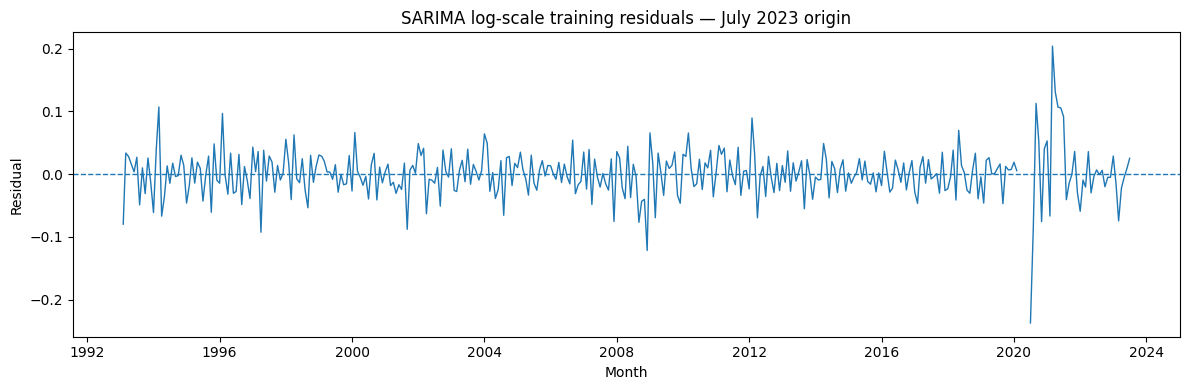

In [ ]:

from IPython.display import display
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

diagnostic_cases = [
    ("Pre-COVID (July 2019)", pd.Timestamp("2019-07-01")),
    ("July 2023", pd.Timestamp("2023-07-01")),
]

model_rows = []
parameter_rows = []
acf_rows = []
ljung_box_rows = []
residuals_2023 = None

for label, train_end in diagnostic_cases:
    diagnostic_train = y.loc[:train_end].copy()

    diagnostic_fit, diagnostic_spec = fit_sarima_for_diagnostics(
        diagnostic_train,
        transform="log",
    )

    model_rows.append({
        "Origin": label,
        "Training_End": train_end.strftime("%Y-%m"),
        "Order": diagnostic_spec["order"],
        "Seasonal_Order": diagnostic_spec["seasonal_order"],
        "AICc": diagnostic_spec["aicc"],
    })

    # Extract the estimated MA coefficients.
    param_names = getattr(diagnostic_fit, "param_names", None)
    if param_names is None:
        param_names = diagnostic_fit.model.param_names

    params = pd.Series(
        np.asarray(diagnostic_fit.params, dtype=float),
        index=param_names,
    )

    ma_params = params.loc[
        params.index.str.contains(
            r"(^ma\.|\.ma\.)",
            case=False,
            regex=True,
        )
    ]

    for term, value in ma_params.items():
        parameter_rows.append({
            "Origin": label,
            "Parameter": term,
            "Estimate": float(value),
        })

    # Keep the monthly timeline and remove diffuse initialization.
    all_residuals = pd.Series(
        np.asarray(diagnostic_fit.resid, dtype=float),
        index=diagnostic_train.index,
        name="Residual",
    )

    residuals = all_residuals.iloc[13:].copy()

    # COVID target observations were masked during training.
    # Preserve those calendar gaps as NaN rather than stitching
    # observations across the missing months.
    residuals.loc[
        residuals.index.isin(COVID_MONTHS)
    ] = np.nan

    residuals = residuals.where(
        np.isfinite(residuals.to_numpy())
    )

    clean = residuals.dropna()

    # Find contiguous monthly segments.
    month_number = clean.index.year * 12 + clean.index.month
    breaks = np.r_[
        0,
        np.flatnonzero(np.diff(month_number) != 1) + 1,
        len(clean),
    ]

    for segment_number, (left, right) in enumerate(
        zip(breaks[:-1], breaks[1:]),
        start=1,
    ):
        segment = clean.iloc[left:right]

        if len(segment) < 3:
            continue

        start = segment.index.min().strftime("%Y-%m")
        end = segment.index.max().strftime("%Y-%m")

        # ACF is calculated within each uninterrupted monthly segment.
        acf_values = acf(
            segment.to_numpy(),
            nlags=min(12, len(segment) - 1),
            fft=False,
        )

        acf_rows.append({
            "Origin": label,
            "Segment": segment_number,
            "Start": start,
            "End": end,
            "N": len(segment),
            "ACF_Lag_1": (
                float(acf_values[1])
                if len(acf_values) > 1
                else np.nan
            ),
            "ACF_Lag_12": (
                float(acf_values[12])
                if len(acf_values) > 12
                else np.nan
            ),
        })

        valid_lags = [
            lag for lag in (12, 24)
            if lag < len(segment)
        ]

        if valid_lags:
            lb = acorr_ljungbox(
                segment.to_numpy(),
                lags=valid_lags,
                model_df=2,
                return_df=True,
            )

            for lag, row in lb.iterrows():
                ljung_box_rows.append({
                    "Origin": label,
                    "Segment": segment_number,
                    "Start": start,
                    "End": end,
                    "N": len(segment),
                    "Lag": int(lag),
                    "LB_Statistic": float(row["lb_stat"]),
                    "P_Value": float(row["lb_pvalue"]),
                })

    if label == "July 2023":
        residuals_2023 = residuals.copy()

print("Selected diagnostic models:")
display(pd.DataFrame(model_rows).round(3))

print("Estimated moving-average coefficients:")
display(pd.DataFrame(parameter_rows).round(4))

print("Residual autocorrelation by contiguous segment:")
display(pd.DataFrame(acf_rows).round(4))

print("Ljung-Box tests by contiguous segment:")
lb_table = pd.DataFrame(ljung_box_rows)
display(
    lb_table.style.format({
        "LB_Statistic": "{:.2f}",
        "P_Value": "{:.3e}",
    })
)

# Plot the original monthly timeline, including the visible COVID gap.
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    residuals_2023.index,
    residuals_2023.values,
    linewidth=1,
)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("SARIMA log-scale residuals — July 2023 origin")
ax.set_xlabel("Month")
ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()



### Residual Diagnostic Findings

The July 2023 training fit selected SARIMA(0,1,1) × (0,1,1)₁₂ using training-only AICc. The residual diagnostics exclude the first 13 observations affected by diffuse initialization and exclude March–June 2020, which were masked during training.

**Pre-COVID segment.** From February 1993 through February 2020, the retained segment contains 325 observations. The lag-1 ACF is approximately -0.236 and the lag-12 ACF is approximately +0.183. The Ljung–Box statistics are approximately 103.8 at lag 12 and 179.0 at lag 24; both tests are highly significant (p < 0.001).

These results demonstrate meaningful residual structure before the COVID gap. The negative lag-1 correlation is consistent with a short-run MA specification that may be overfitting or inadequately capturing the dependence. It is a diagnostic warning, not proof of overfitting by itself.

**Post-gap segment.** From July 2020 through July 2023, only 37 observations remain. The Ljung–Box p-values are approximately 0.070 at lag 12 and 0.519 at lag 24. Given the short segment, these results should not be interpreted as evidence that the model is fully adequate or that residual dependence has disappeared.

**Pre-COVID comparison.** The July 2019 origin has no COVID observations in its training data, and its AICc-selected model is SARIMA(0,1,2) × (0,1,1)₁₂. The MA(1) coefficient is approximately -0.79, compared with approximately -0.50 in the July 2023 fit.

The differing selected orders and MA coefficients suggest that the fitted dynamics are sensitive to the training period and subsequent sales regime. The pre-COVID fit helps distinguish persistent model-specification issues from changes associated with the COVID-era data, although this comparison alone does not prove the cause of the parameter change.

Residual diagnostics remain secondary to out-of-sample validation. They do not change the pre-declared validation folds, the selection rule, or the locked test protocol.


## Selecting the Finalists

Finalist selection follows the rule defined before model comparison: rank the candidate configurations by their pooled validation RelMAE against seasonal naive and retain at most two.

When pooled scores are tied, the declared complexity ranking determines the preference. The best individual fold, the COVID stress results, and the locked test folds are not used to select finalists.

The top-ranked candidate is the leading model for further investigation, and the second-ranked candidate provides a comparison point. Being selected as a finalist does not automatically mean that a model has passed the acceptance criteria.

The success bar remains pooled RelMAE ≤ 0.90 and improvement over seasonal naive in at least four of six folds. If neither finalist meets both conditions, the conclusion must report that the current modeling stage has not achieved the required improvement.

In [13]:
candidate_summary = (
    model_summary.loc[
        model_summary["Model"].isin(candidate_forecasters)
    ]
    .sort_values(
        ["Pooled_RelMAE_vs_SN", "Complexity_Rank"],
        ascending=[True, True],
    )
    .reset_index(drop=True)
)

finalists = candidate_summary.head(2)

print("Candidate ranking:")
display(
    candidate_summary[
        [
            "Model",
            "Pooled_RelMAE_vs_SN",
            "Pooled_RelMAE_vs_Drift",
            "Folds_Beating_SN",
            "Mean_Bias",
            "Mean_December_Abs_Pct_Error",
        ]
    ].round(3)
)

print("\nSelected finalists:")
display(finalists.round(3))

Candidate ranking:


,Model,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN,Mean_Bias,Mean_December_Abs_Pct_Error
0,SARIMA seasonal (log),1.000,1.075,4,227.610,2.348
1,SARIMA seasonal (raw),1.051,1.130,4,69.227,3.104
2,ETS (AICc-selected),1.055,1.135,3,-16.684,2.510
3,"Prophet multiplicative, cps=0.01",1.304,1.402,1,-83.812,5.073
4,"Prophet multiplicative, cps=0.2",1.396,1.500,2,-188.062,4.952
5,"SARIMAX log levels + month dummies (d=1, D=0)",1.473,1.583,0,480.171,9.537
6,"Prophet multiplicative, cps=0.05",1.482,1.593,0,-31.733,5.584
7,"Prophet additive, cps=0.01",1.836,1.973,0,77.390,5.762
8,"Prophet additive, cps=0.2",1.912,2.056,0,-138.788,6.310
9,"Prophet additive, cps=0.05",1.988,2.137,0,34.005,5.848



Selected finalists:


,Model,Pooled_RelMAE_vs_SN,Pooled_RelMAE_vs_Drift,Folds_Beating_SN,Mean_Bias,Mean_December_Abs_Pct_Error,Complexity_Rank
0,SARIMA seasonal (log),1.000,1.075,4,227.610,2.348,3
1,SARIMA seasonal (raw),1.051,1.130,4,69.227,3.104,2



### Finalist Selection Results

The corrected ranking selects two seasonal SARIMA configurations as finalists:

1. **Log-scale seasonal SARIMA:** pooled RelMAE of approximately 1.000, beating seasonal naive in four of six validation folds.
2. **Raw-scale seasonal SARIMA:** pooled RelMAE of approximately 1.051, also beating seasonal naive in four of six folds.

The log-scale finalist has a mean signed bias of approximately +$227.6 million and a mean absolute December percentage error of approximately 2.35%. The raw-scale finalist has a mean signed bias of approximately +$69.2 million and a mean absolute December percentage error of approximately 3.10%.

The log-scale model ranks first by pooled RelMAE, while the raw-scale model has lower mean signed bias. These metrics describe different aspects of forecast performance and should be interpreted separately.

Neither finalist meets the complete acceptance rule because neither reaches pooled RelMAE ≤ 0.90. These models are the strongest candidates among those evaluated, not evidence that the required forecasting improvement has been achieved. The locked test folds remain reserved for the final evaluation after the model-selection process is complete.


In [14]:
winner = candidate_summary.iloc[0]
winner_name = winner["Model"]

winner_folds = fold_metrics.loc[
    fold_metrics["Model"] == winner_name
]

worst_fold = winner_folds.sort_values(
    "RelMAE_vs_SN",
    ascending=False,
).iloc[0]

worst_month = (
    calendar_month_errors.loc[
        calendar_month_errors["Model"] == winner_name
    ]
    .sort_values("MAE", ascending=False)
    .iloc[0]
)

passes_bar = (
    winner["Pooled_RelMAE_vs_SN"] <= 0.90
    and winner["Folds_Beating_SN"] >= 4
)

print(
    f"Winner: {winner_name}\n"
    f"Pooled RelMAE vs seasonal naive: "
    f"{winner['Pooled_RelMAE_vs_SN']:.3f}\n"
    f"Pooled RelMAE vs selected drift: "
    f"{winner['Pooled_RelMAE_vs_Drift']:.3f}\n"
    f"Validation folds beating seasonal naive: "
    f"{int(winner['Folds_Beating_SN'])}/6\n"
    f"Meets pre-declared success bar: {passes_bar}\n"
    f"Worst fold: {worst_fold['Origin']} "
    f"(RelMAE={worst_fold['RelMAE_vs_SN']:.3f})\n"
    f"Worst calendar month by MAE: "
    f"{worst_month['Calendar_Month']} "
    f"(MAE=${worst_month['MAE']:.1f}M)\n"
    f"Mean signed bias: ${winner['Mean_Bias']:.1f}M\n"
    f"Mean absolute December % error: "
    f"{winner['Mean_December_Abs_Pct_Error']:.2f}%"
)

Winner: SARIMA seasonal (log)
Pooled RelMAE vs seasonal naive: 1.000
Pooled RelMAE vs selected drift: 1.075
Validation folds beating seasonal naive: 4/6
Meets pre-declared success bar: False
Worst fold: 2018-07 (RelMAE=1.630)
Worst calendar month by MAE: March (MAE=$871.9M)
Mean signed bias: $227.6M
Mean absolute December % error: 2.35%


## Forecasts Versus Actual Sales

The forecast plots compare actual sales with seasonal naive and the two leading candidate models for two validation origins: July 2018 and July 2023.

These periods provide different historical contexts while remaining outside the locked test folds. The plots make it possible to assess how well each forecast reproduces the overall sales level and the recurring calendar pattern over the 12-month horizon.

The comparison is especially useful for identifying visible under- or over-forecasting, differences in the December peak, and periods in which candidate models diverge from one another.

The plots complement the numerical metrics rather than replacing them. Visual fit alone is not used to rank the models, and neither plotted fold is used to override the pooled RelMAE selection rule.

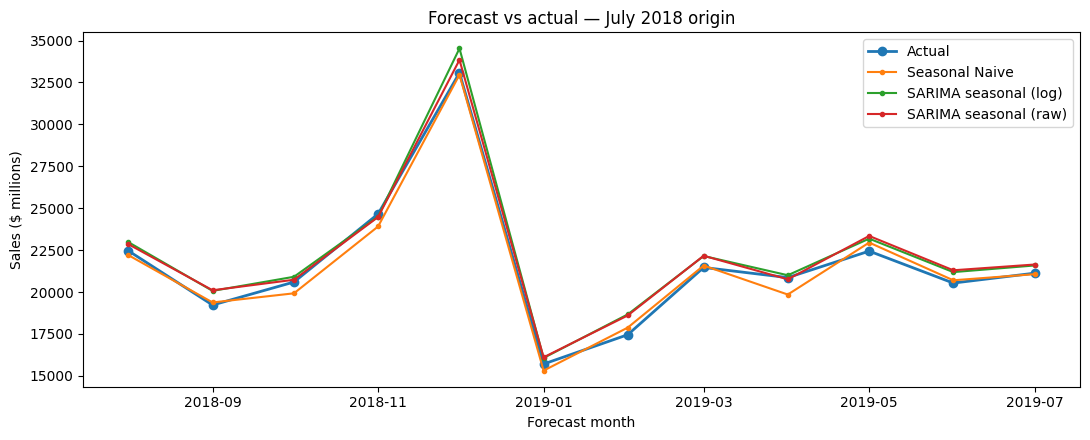

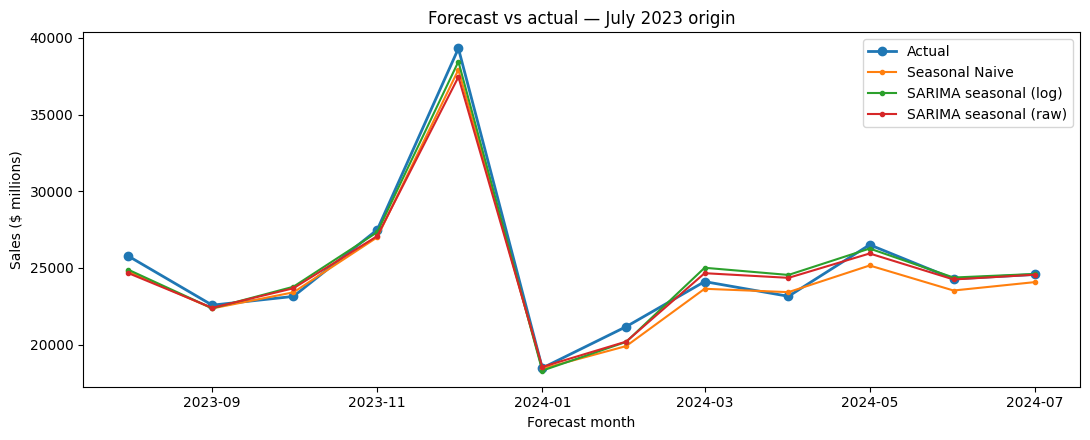

In [15]:
plot_models = [
    "Seasonal Naive",
    *finalists["Model"].tolist(),
]

for origin in ("2018-07", "2023-07"):
    subset = predictions.loc[
        (predictions["Origin"] == origin)
        & predictions["Model"].isin(plot_models)
    ].copy()

    actual_line = (
        subset[["Date", "Actual"]]
        .drop_duplicates("Date")
        .sort_values("Date")
    )

    fig, ax = plt.subplots(figsize=(11, 4.5))

    ax.plot(
        actual_line["Date"],
        actual_line["Actual"],
        marker="o",
        label="Actual",
        linewidth=2,
    )

    for model_name in plot_models:
        model_line = (
            subset.loc[subset["Model"] == model_name]
            .sort_values("Date")
        )

        if not model_line.empty:
            ax.plot(
                model_line["Date"],
                model_line["Forecast"],
                marker=".",
                label=model_name,
            )

    ax.set_title(
        f"Forecast vs actual — July {origin[:4]} origin"
    )
    ax.set_xlabel("Forecast month")
    ax.set_ylabel("Sales ($ millions)")
    ax.legend()
    plt.tight_layout()
    plt.show()


## COVID Stress Folds: Separate Robustness Assessment

The July 2020 and July 2021 origins are reported separately as stress tests. Their results are not used to select finalists or calculate the primary validation ranking.

**July 2020 origin.** Seasonal naive has an MAE of approximately $7,040 million. Log-scale seasonal SARIMA has an MAE of approximately $3,058 million, or 0.434 times seasonal naive's error. Raw-scale seasonal SARIMA has an MAE of approximately $3,221 million, or 0.458 times seasonal naive's error.

**July 2021 origin.** Seasonal naive has an MAE of approximately $3,269 million. Log-scale seasonal SARIMA has an MAE of approximately $2,150 million, or 0.658 times seasonal naive's error. Raw-scale seasonal SARIMA has an MAE of approximately $2,192 million, or 0.671 times seasonal naive's error.

The error direction is also informative. Log-scale SARIMA's mean signed bias changes from approximately -$2,376 million for the July 2020 origin to +$2,150 million for the July 2021 origin. Raw-scale SARIMA changes from approximately -$2,077 million to +$2,083 million. Seasonal naive continues to under-forecast in both stress folds, with bias around -$3,595 million and -$3,147 million, respectively.

This sign reversal illustrates how strongly the forecasts are affected by the abnormal sales path and the comparison year. Repeating a COVID-distorted year can be particularly unreliable, while the fitted SARIMA models reduce MAE substantially in these two stress periods.

The balanced conclusion is that the seasonal SARIMA finalists do not demonstrate a pooled improvement over seasonal naive during the primary validation folds—the log-scale model is approximately at parity with pooled RelMAE of 1.000—but they provide evidence of better robustness in the two tested COVID-related stress folds. This is a limited historical robustness result, not proof of future performance and not a model-selection criterion.


In [16]:
stress_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    drift_name: baseline_forecasters[drift_name],
}

for model_name in finalists["Model"]:
    stress_forecasters[model_name] = candidate_forecasters[model_name]


stress_results = []

for model_name, forecast_fn in stress_forecasters.items():
    result = evaluate(
        forecast_fn,
        y,
        origins=STRESS_ORIGINS,
        mask=False,
    )

    result["Model"] = model_name
    stress_results.append(result)

stress_table = pd.concat(
    stress_results,
    ignore_index=True,
)

display(
    stress_table[
        [
            "Model",
            "Origin",
            "MAE",
            "RMSE",
            "Bias",
            "RelMAE_vs_SN",
            "December_Abs_Pct_Error",
        ]
    ].round(3)
)

,Model,Origin,MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,Seasonal Naive,2020-07,7039.750,9157.309,-3594.583,1.000,12.286
1,Seasonal Naive,2021-07,3269.167,4077.560,-3146.667,1.000,18.845
2,Drift: trailing-12-month mean YoY,2020-07,7235.858,9151.646,-3189.279,1.028,14.874
3,Drift: trailing-12-month mean YoY,2021-07,3269.167,4077.560,-3146.667,1.000,18.845
4,SARIMA seasonal (log),2020-07,3058.039,3936.098,-2375.713,0.434,2.751
5,SARIMA seasonal (log),2021-07,2149.735,2278.487,2149.735,0.658,7.542
6,SARIMA seasonal (raw),2020-07,3221.355,4076.058,-2076.691,0.458,3.804
7,SARIMA seasonal (raw),2021-07,2192.457,2468.051,2083.315,0.671,1.146
